# dronefuse walkthrough: raw sensors → dead reckoning → linear KF → error-state EKF

Figure-eight, 60 s, seed 0, position fixes dropped between 30 s and 35 s. Everything is
reproducible from the package; this notebook only plots.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

from dronefuse.estimators import make_estimator
from dronefuse.estimators.base import InitConfig
from dronefuse.metrics import NEES_DOF, chi2_bounds, format_metrics_table
from dronefuse.pipeline import run_pipeline
from dronefuse.plots import COLORS, LABELS
from dronefuse.sensors import SensorConfig
from dronefuse.simulate import perturbed_initial_state

DROPOUT = (30.0, 35.0)
result = run_pipeline("figure8", ["dr", "kf", "ekf"], seed=0, duration=60.0, dropouts=[DROPOUT])
truth, log = result.truth, result.log

## 1. Raw sensors
The accelerometer measures specific force in the body frame (≈ +9.81 m/s² on z at rest),
plus a slowly drifting bias and white noise. Position fixes arrive at 5 Hz with 0.3 m noise,
and vanish during the dropout.

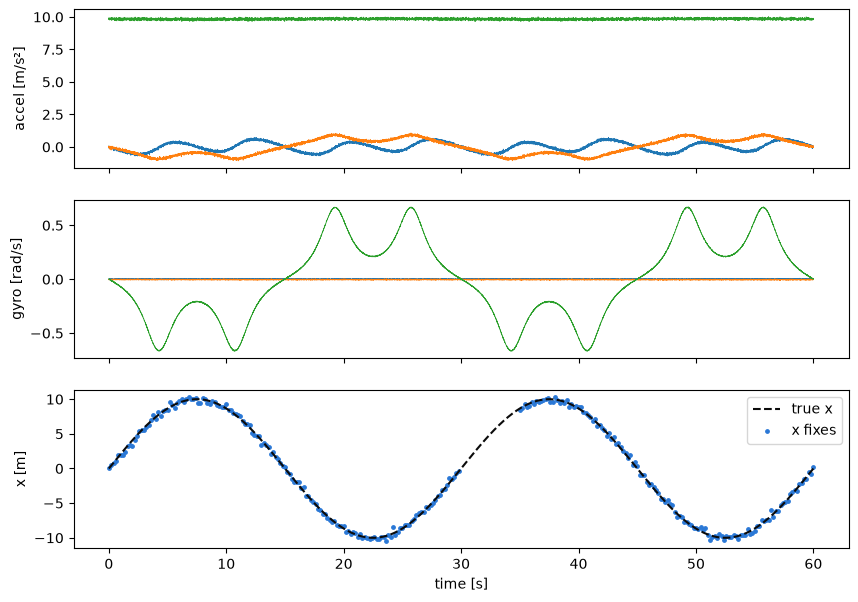

In [2]:
fig, axes = plt.subplots(3, 1, figsize=(10, 7), sharex=True)
axes[0].plot(truth.t, log.accel, lw=0.6)
axes[0].set_ylabel("accel [m/s²]")
axes[1].plot(truth.t, log.gyro, lw=0.6)
axes[1].set_ylabel("gyro [rad/s]")
has_fix = ~np.isnan(log.fix[:, 0])
axes[2].plot(truth.t, truth.pos[:, 0], color=COLORS["truth"], ls="--", label="true x")
axes[2].scatter(truth.t[has_fix], log.fix[has_fix, 0], s=6, color=COLORS["ekf"], label="x fixes")
axes[2].set_ylabel("x [m]")
axes[2].set_xlabel("time [s]")
axes[2].legend()
plt.show()

## 2. Dead reckoning drifts
Integrating the IMU alone: the accelerometer bias integrates twice into position, and the
gyro bias tilts the estimated attitude so gravity leaks into the horizontal axes.

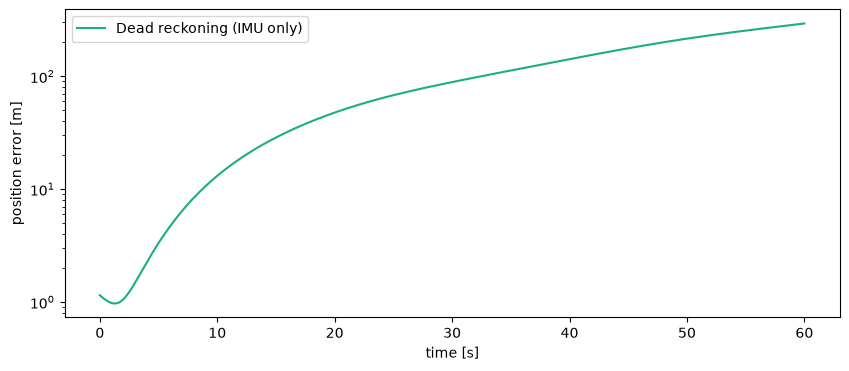

In [3]:
err = {name: np.linalg.norm(t.pos - truth.pos, axis=1) for name, t in result.trajectories.items()}
plt.figure(figsize=(10, 4))
plt.plot(truth.t, err["dr"], color=COLORS["dr"], label=LABELS["dr"])
plt.yscale("log")
plt.xlabel("time [s]")
plt.ylabel("position error [m]")
plt.legend()
plt.show()

## 3. Linear KF: position fixes only
A constant-velocity model with position measurements smooths the fixes but lags in turns and
knows nothing about attitude. During the dropout it can only extrapolate its last velocity.

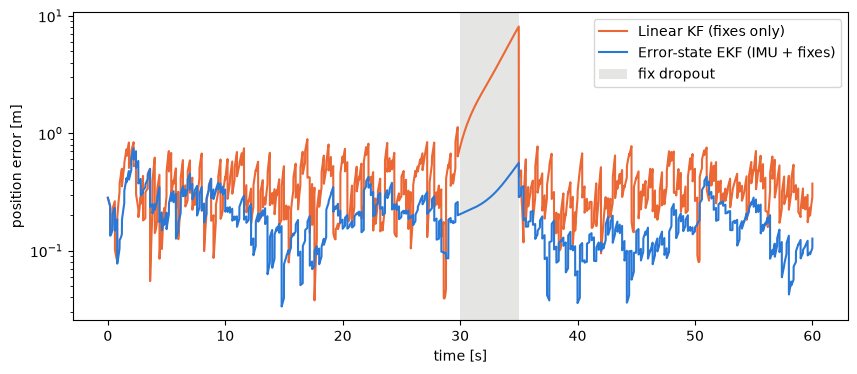

In [4]:
plt.figure(figsize=(10, 4))
for name in ["kf", "ekf"]:
    plt.plot(truth.t, err[name], color=COLORS[name], label=LABELS[name])
plt.axvspan(*DROPOUT, color="#52514e", alpha=0.15, lw=0, label="fix dropout")
plt.yscale("log")
plt.xlabel("time [s]")
plt.ylabel("position error [m]")
plt.legend()
plt.show()

## 4. Error-state EKF: IMU + fixes, with bias estimation
The EKF uses the IMU between fixes, estimates the biases, and keeps a covariance that matches
its actual error. The NEES test checks that: a consistent filter stays inside the chi-square
band ~95 % of the time, and its mean NEES is close to the state dimension (6 here).

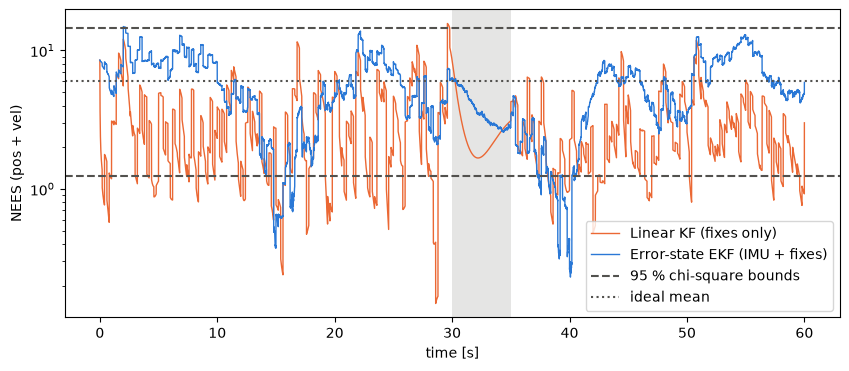

In [5]:
lo, hi = chi2_bounds(NEES_DOF)
plt.figure(figsize=(10, 4))
for name in ["kf", "ekf"]:
    plt.plot(truth.t, result.metrics[name].nees, color=COLORS[name], lw=1.0, label=LABELS[name])
plt.axhline(lo, color="#52514e", ls="--")
plt.axhline(hi, color="#52514e", ls="--", label="95 % chi-square bounds")
plt.axhline(NEES_DOF, color="#52514e", ls=":", label="ideal mean")
plt.axvspan(*DROPOUT, color="#52514e", alpha=0.15, lw=0)
plt.yscale("log")
plt.xlabel("time [s]")
plt.ylabel("NEES (pos + vel)")
plt.legend()
plt.show()

## 5. Estimated vs true IMU biases
Rerun the EKF step by step on the same log to record the bias states.

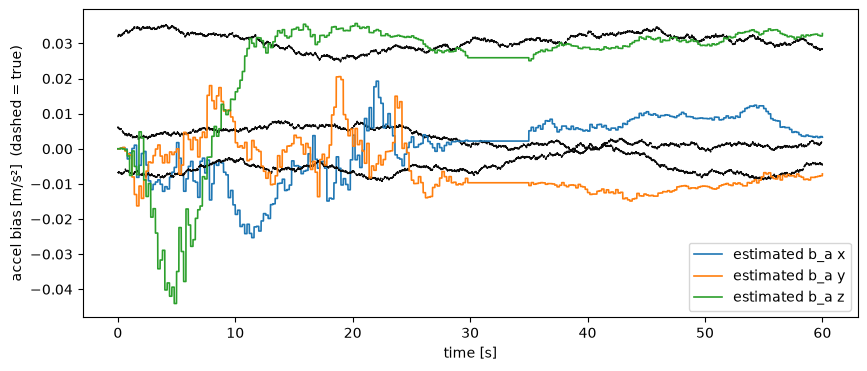

In [6]:
sensor_cfg = SensorConfig(dropouts=(DROPOUT,))
init = perturbed_initial_state(truth, InitConfig(), seed=0)
ekf = make_estimator("ekf", init, sensor_cfg, InitConfig())
est_bias = np.empty((len(log), 3))
for i in range(len(log)):
    if i > 0:
        ekf.predict(log.imu(i - 1), log.dt)
    fix = log.fix_at(i)
    if fix is not None:
        ekf.update(fix)
    est_bias[i] = ekf.nominal.accel_bias  # type: ignore[attr-defined]

plt.figure(figsize=(10, 4))
for k, axis in enumerate("xyz"):
    plt.plot(truth.t, log.accel_bias[:, k], color=COLORS["truth"], ls="--", lw=1.0)
    plt.plot(truth.t, est_bias[:, k], lw=1.2, label=f"estimated b_a {axis}")
plt.xlabel("time [s]")
plt.ylabel("accel bias [m/s²]  (dashed = true)")
plt.legend()
plt.show()

## 6. Summary

In [7]:
print(format_metrics_table(list(result.metrics.values())))

| Estimator | Pos RMSE [m] | Vel RMSE [m/s] | Max pos err [m] | Mean NEES (ideal 6) | NEES in 95 % bounds |
|---|---:|---:|---:|---:|---:|
| DR | 139.205 | 5.479 | 293.93 | n/a | n/a |
| KF | 1.200 | 0.880 | 8.11 | 3.01 | 83.0 % |
| EKF | 0.229 | 0.151 | 0.74 | 5.58 | 93.7 % |
